## MOUNT DRIVE

In [7]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


CONFIGURE DATASET PATHS


In [9]:
from pathlib import Path




ZIP_PATH = Path(
    "/content/drive/MyDrive/prepared_landmark_dataset.rar"
)


EXTRACT_DIR = Path("/content/drive/MyDrive/SIFT_Landmark_Extracted")

# ---

QUERY_IMAGE_PATH = None

print("Drive connected.")
print("ZIP path:", ZIP_PATH)
print("Extraction folder:", EXTRACT_DIR)

if not ZIP_PATH.exists():
    print("\nACTION REQUIRED:")
    print("Replace ZIP_PATH with the real path of your ZIP file.")
else:
    print("ZIP file found successfully.")

Drive connected.
ZIP path: /content/drive/MyDrive/prepared_landmark_dataset.rar
Extraction folder: /content/drive/MyDrive/SIFT_Landmark_Extracted
ZIP file found successfully.


In [10]:
import sys
# Install patool to handle RAR extraction in Colab
!pip install patool

In [11]:
import patoolib
import os

# Create the destination directory if it doesn't exist
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Extracting {ZIP_PATH} to {EXTRACT_DIR}...")

try:
    patoolib.extract_archive(str(ZIP_PATH), outdir=str(EXTRACT_DIR))
    print("\nExtraction completed successfully!")
    print("You should now be able to see the folder and its contents in your Google Drive.")
except Exception as e:
    print(f"\nAn error occurred during extraction: {e}")

INFO patool: Extracting /content/drive/MyDrive/prepared_landmark_dataset.rar ...
INFO patool: running '/usr/bin/unrar' 'x' '-kb' '-or' '--' '/content/drive/MyDrive/prepared_landmark_dataset.rar'


Extracting /content/drive/MyDrive/prepared_landmark_dataset.rar to /content/drive/MyDrive/SIFT_Landmark_Extracted...


INFO patool: ... /content/drive/MyDrive/prepared_landmark_dataset.rar extracted to `/content/drive/MyDrive/SIFT_Landmark_Extracted'.



Extraction completed successfully!
You should now be able to see the folder and its contents in your Google Drive.


# INSTALL AND IMPORT LIBRARIES


In [12]:




import sys
import subprocess
import importlib.util

# Install OpenCV with SIFT support if it is unavailable.
try:
    import cv2
    if not hasattr(cv2, "SIFT_create"):
        raise ImportError("SIFT is not available")
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "opencv-contrib-python-headless"
    ])

import os
import time
import zipfile
import shutil
import random
import warnings
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from google.colab import drive

# Reproducible visualization sampling
random.seed(42)
np.random.seed(42)

# Attractive, coordinated palette
SAGE = "#A8BFA3"
DARK_SAGE = "#55765A"
TEA_PINK = "#E8B7C8"
LAVENDER = "#C8B6E2"
PURPLE = "#8064A2"
CREAM = "#FAF4EC"
INK = "#373344"
PALETTE = [SAGE, TEA_PINK, LAVENDER, PURPLE, "#D9C5A1"]

sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.facecolor"] = CREAM
plt.rcParams["axes.facecolor"] = "#FFFCF8"
plt.rcParams["axes.edgecolor"] = SAGE
plt.rcParams["axes.labelcolor"] = INK
plt.rcParams["text.color"] = INK
plt.rcParams["xtick.color"] = INK
plt.rcParams["ytick.color"] = INK
plt.rcParams["axes.titleweight"] = "bold"

print("Python version:", sys.version.split()[0])
print("OpenCV version:", cv2.__version__)
print("SIFT available:", hasattr(cv2, "SIFT_create"))
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

assert hasattr(cv2, "SIFT_create"), (
    "SIFT is unavailable. Check the OpenCV installation."
)

print("\nSetup completed successfully!")

Python version: 3.13.16
OpenCV version: 5.0.0
SIFT available: True
NumPy version: 2.1.3
Pandas version: 2.2.3

Setup completed successfully!


## DATASET CONFIGURATION AND VALIDATION

In [39]:

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"
}

def get_images(folder):
    """Return image files directly inside a folder."""
    folder = Path(folder)
    if not folder.is_dir():
        return []

    return sorted([
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ])

def find_landmark_roots(base_dir):
    """Find directories containing at least five image-bearing subfolders."""
    candidates = []

    for current, subdirs, _ in os.walk(base_dir):
        current_path = Path(current)

        landmark_folders = [
            current_path / name for name in subdirs
            if get_images(current_path / name)
        ]

        if len(landmark_folders) >= 5:
            candidates.append(current_path)

    return candidates

candidate_roots = find_landmark_roots(EXTRACT_DIR)

print("Possible landmark database folders:")
for root in candidate_roots:
    print(" -", root)



DATASET_ROOT = (
    candidate_roots[0] if candidate_roots else EXTRACT_DIR
)

print("\nSelected dataset root:", DATASET_ROOT)



landmark_folders = sorted([
    p for p in DATASET_ROOT.iterdir()
    if p.is_dir() and get_images(p)
]) if DATASET_ROOT.is_dir() else []

dataset_summary = []

for folder in landmark_folders:
    images = get_images(folder)
    readable_count = 0

    for image_path in images:
        image = cv2.imread(str(image_path))
        if image is not None:
            readable_count += 1

    dataset_summary.append({
        "Landmark": folder.name,
        "Image Files": len(images),
        "Readable Images": readable_count,
        "Folder": str(folder)
    })

dataset_df = pd.DataFrame(dataset_summary)

if dataset_df.empty:
    raise ValueError(
        "No landmark folders found. Set DATASET_ROOT to the folder "
        "directly containing your landmark subfolders."
    )

display(dataset_df[["Landmark", "Image Files", "Readable Images"]])

print("\nNumber of landmarks:", len(dataset_df))
print("Total image files:", int(dataset_df["Image Files"].sum()))

if len(dataset_df) < 5:
    warnings.warn(
        "The assignment requires at least five landmarks. "
        "Add more landmark folders before proceeding."
    )

if (dataset_df["Readable Images"] == 0).any():
    warnings.warn(
        "Some landmark folders have no readable images. "
        "Check their image formats and file integrity."
    )

Selected dataset root: /content/drive/MyDrive/SIFT_Landmark_Extracted/prepared_landmark_dataset/reference


,Landmark,Image Files,Readable Images
0,christ_the_reedemer,516,516
1,eiffel_tower,624,624
2,great_wall_of_china,626,626
3,roman_colosseum,630,630
4,taj_mahal,252,252



Number of landmarks: 5
Total image files: 2648


/tmp/ipykernel_2301/3212547625.py:3: UserWarning: 
The palette list has fewer values (5) than needed (6) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(


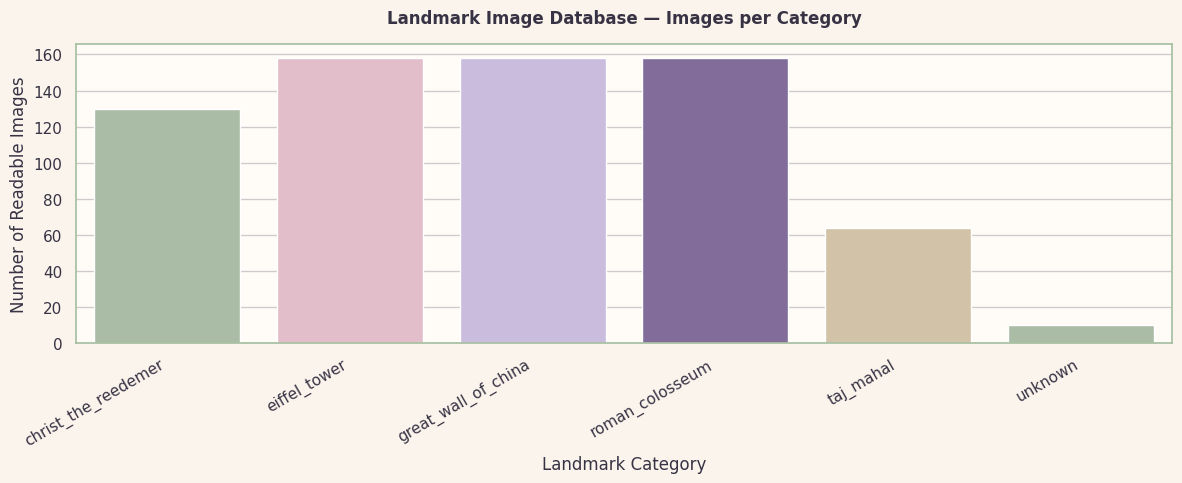

In [14]:

plt.figure(figsize=(12, 5))

sns.barplot(
    data=dataset_df,
    x="Landmark",
    y="Readable Images",
    hue="Landmark",
    palette=PALETTE,
    legend=False
)

plt.title("Landmark Image Database — Images per Category", pad=15)
plt.xlabel("Landmark Category")
plt.ylabel("Number of Readable Images")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# SIFT FEATURE EXTRACTION

In [15]:

sift = cv2.SIFT_create(
    nfeatures=2500,
    contrastThreshold=0.03,
    edgeThreshold=10,
    sigma=1.6
)

reference_database = []
feature_records = []

for _, row in dataset_df.iterrows():
    landmark = row["Landmark"]
    folder = Path(row["Folder"])

    for image_path in get_images(folder):
        image_bgr = cv2.imread(str(image_path))

        if image_bgr is None:
            print("Skipping unreadable image:", image_path)
            continue

        gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

        keypoints, descriptors = sift.detectAndCompute(gray, None)

        if descriptors is None or len(keypoints) == 0:
            print("No SIFT features detected:", image_path.name)
            continue

        record = {
            "landmark": landmark,
            "path": str(image_path),
            "image_bgr": image_bgr,
            "gray": gray,
            "keypoints": keypoints,
            "descriptors": descriptors,
            "width": gray.shape[1],
            "height": gray.shape[0]
        }

        reference_database.append(record)

        feature_records.append({
            "Landmark": landmark,
            "Image": image_path.name,
            "Width": gray.shape[1],
            "Height": gray.shape[0],
            "Keypoints": len(keypoints),
            "Descriptor Dimensions": descriptors.shape[1]
        })

feature_df = pd.DataFrame(feature_records)

if not reference_database:
    raise ValueError(
        "No reference descriptors were generated. "
        "Check that your images are readable and contain visual details."
    )

if len(set(item["landmark"] for item in reference_database)) < 5:
    raise ValueError(
        "Fewer than five landmarks have usable SIFT features. "
        "Check your dataset and add suitable reference images."
    )

display(feature_df.head(15))

print("Usable reference images:", len(reference_database))
print("Landmarks with usable descriptors:",
      len(set(r["landmark"] for r in reference_database)))

,Landmark,Image,Width,Height,Keypoints,Descriptor Dimensions
0,christ_the_reedemer,00d2585f75(1).jpg,594,395,880,128
1,christ_the_reedemer,00d2585f75.jpg,594,395,880,128
2,christ_the_reedemer,07f0b2ec5b(1).jpg,183,275,248,128
3,christ_the_reedemer,07f0b2ec5b.jpg,183,275,248,128
4,christ_the_reedemer,0ca3b8d570(1).jpg,276,183,548,128
5,christ_the_reedemer,0ca3b8d570.jpg,276,183,548,128
6,christ_the_reedemer,0d00878384(1).jpg,272,185,516,128
7,christ_the_reedemer,0d00878384.jpg,272,185,516,128
8,christ_the_reedemer,0e0236c5be(1).jpg,784,410,599,128
9,christ_the_reedemer,0e0236c5be.jpg,784,410,599,128


Usable reference images: 678
Landmarks with usable descriptors: 6


# detected keypoints

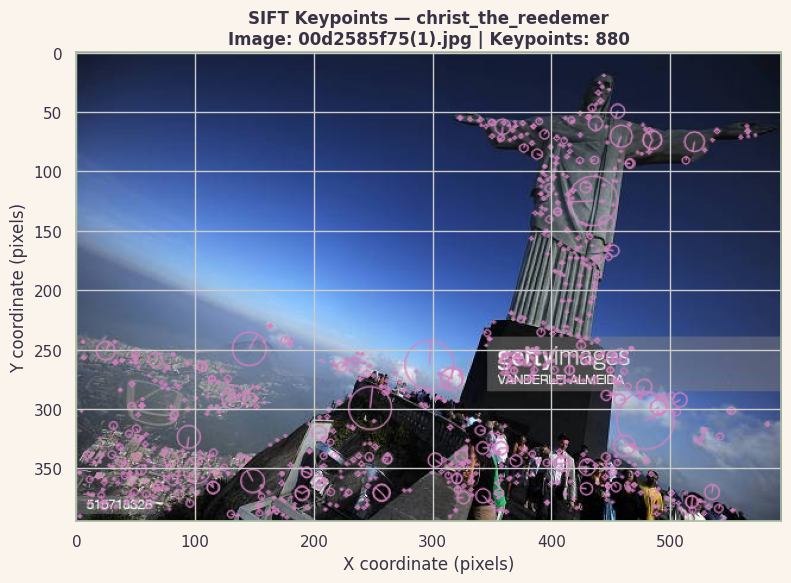

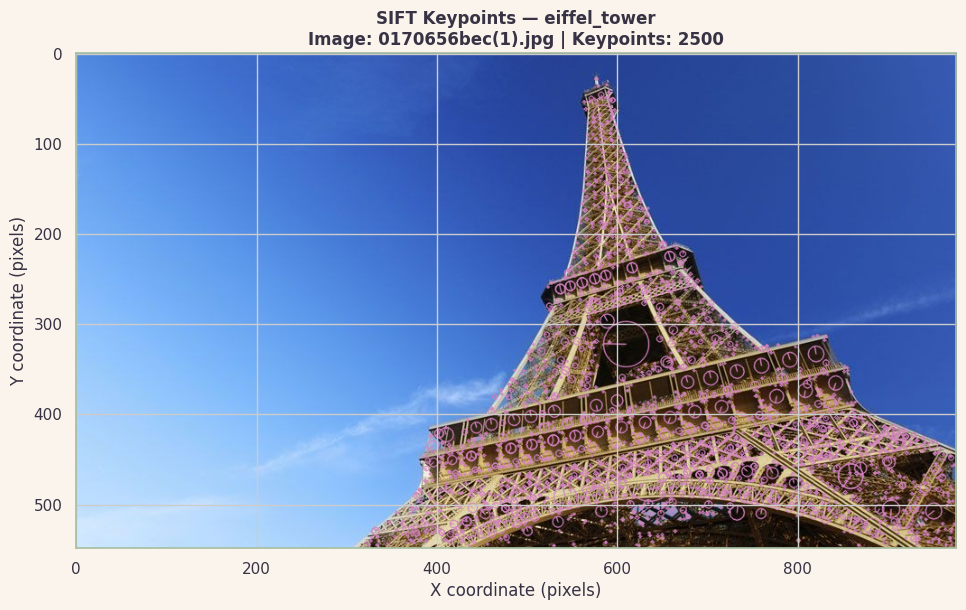

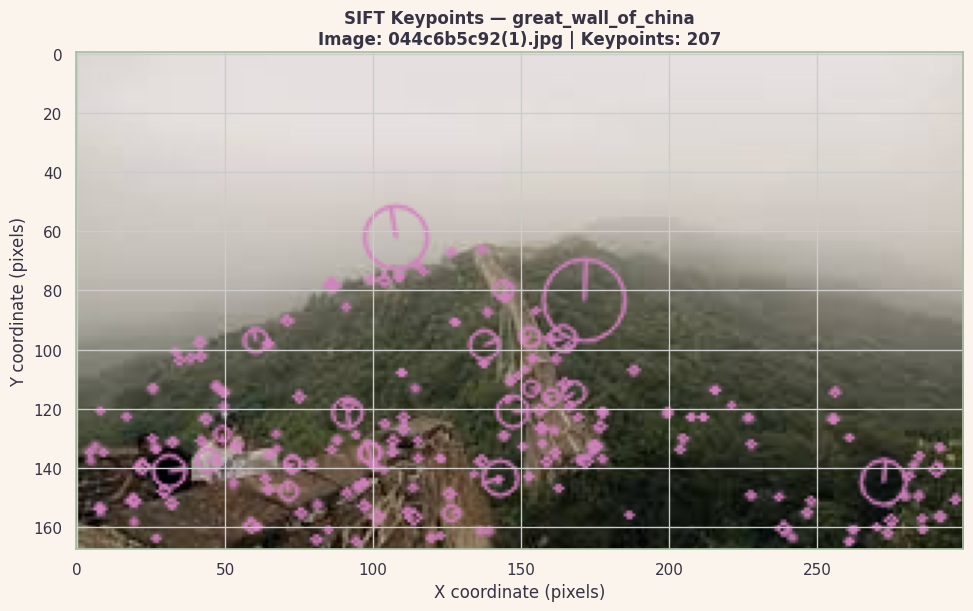

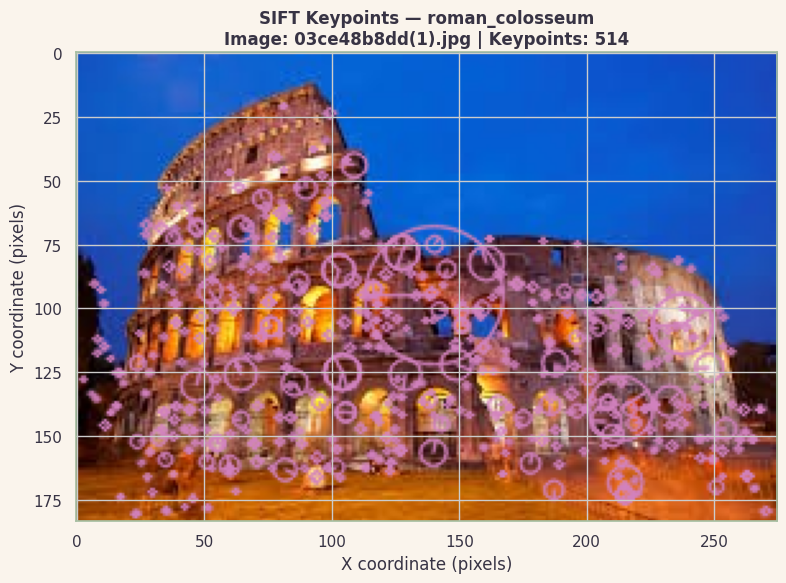

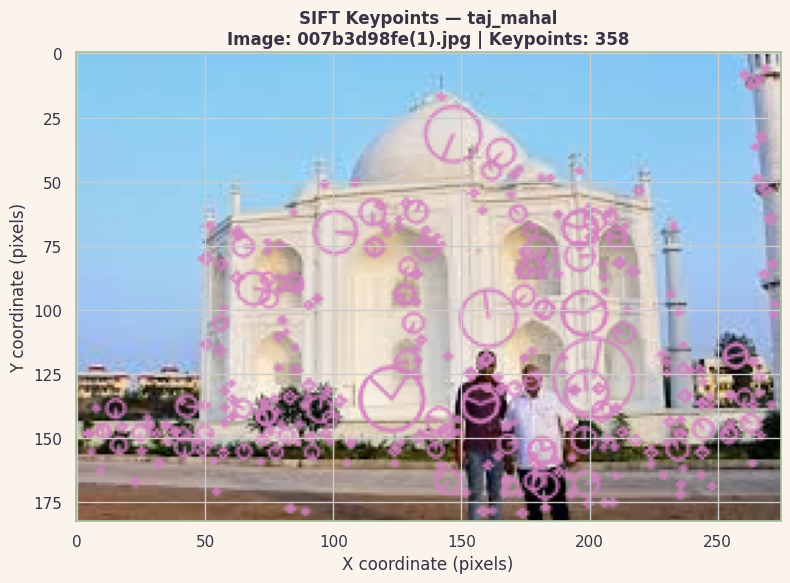

In [16]:


def show_keypoints(record, max_width=850):
    image = record["image_bgr"]

    visual = cv2.drawKeypoints(
        image,
        record["keypoints"],
        None,
        color=(190, 130, 210),
        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
    )

    visual = cv2.cvtColor(visual, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(visual)
    plt.title(
        f"SIFT Keypoints — {record['landmark']}\n"
        f"Image: {Path(record['path']).name} | "
        f"Keypoints: {len(record['keypoints'])}"
    )
    plt.xlabel("X coordinate (pixels)")
    plt.ylabel("Y coordinate (pixels)")
    plt.axis("on")
    plt.tight_layout()
    plt.show()

# Show one reference image per landmark
shown_landmarks = set()

for record in reference_database:
    if record["landmark"] not in shown_landmarks:
        show_keypoints(record)
        shown_landmarks.add(record["landmark"])

    if len(shown_landmarks) >= 5:
        break

# average feature counts

,Landmark,mean,median,min,max,count
0,christ_the_reedemer,979.9,547.0,58,2501,130
1,eiffel_tower,1207.6,670.0,60,2501,158
2,great_wall_of_china,1336.9,740.0,32,2502,158
3,roman_colosseum,1219.0,763.0,255,2501,158
4,taj_mahal,1128.1,483.5,246,2500,64
5,unknown,1251.8,1136.0,233,2500,10


/tmp/ipykernel_2301/1073289697.py:12: UserWarning: 
The palette list has fewer values (5) than needed (6) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(


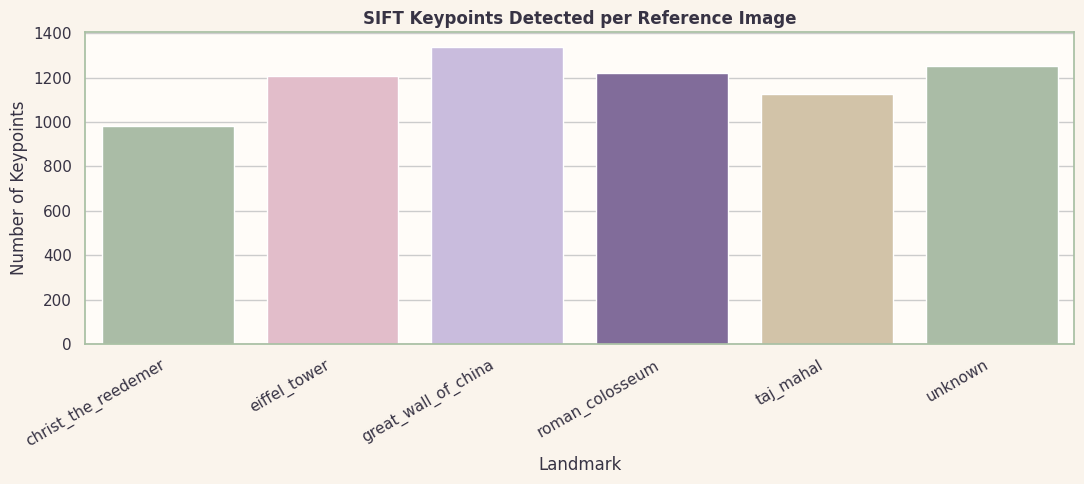

In [17]:

feature_stats = (
    feature_df.groupby("Landmark")["Keypoints"]
    .agg(["mean", "median", "min", "max", "count"])
    .round(1)
    .reset_index()
)

display(feature_stats)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=feature_df,
    x="Landmark",
    y="Keypoints",
    hue="Landmark",
    palette=PALETTE,
    legend=False,
    errorbar=None
)

plt.title("SIFT Keypoints Detected per Reference Image")
plt.xlabel("Landmark")
plt.ylabel("Number of Keypoints")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# QUERY IMAGE INPUT AND FEATURE EXTRACTION

Query image: 0016510b5c.jpg
Image dimensions: 828 x 466
Query keypoints: 1136


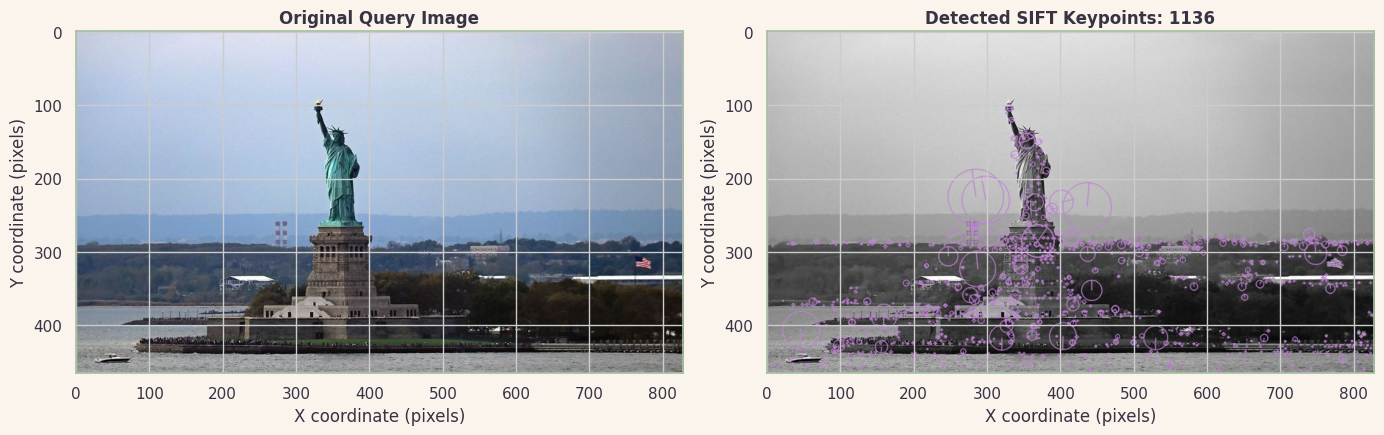

In [21]:


# Pointing to a specific, actual image file from your query directory
QUERY_IMAGE_PATH = "/content/drive/MyDrive/SIFT_Landmark_Extracted/prepared_landmark_dataset/query/unknown/0016510b5c.jpg"

QUERY_IMAGE_PATH = Path(QUERY_IMAGE_PATH)

if not QUERY_IMAGE_PATH.is_file():
    raise FileNotFoundError(
        f"Query image not found: {QUERY_IMAGE_PATH}\n"
        "Replace QUERY_IMAGE_PATH with your actual query image path."
    )

query_bgr = cv2.imread(str(QUERY_IMAGE_PATH))

if query_bgr is None:
    raise ValueError(
        "OpenCV could not read the query image. "
        "Check its format and file integrity."
    )

query_gray = cv2.cvtColor(query_bgr, cv2.COLOR_BGR2GRAY)

query_keypoints, query_descriptors = sift.detectAndCompute(
    query_gray, None
)

if query_descriptors is None or len(query_keypoints) < 2:
    raise ValueError(
        "The query image has too few SIFT features for KNN matching. "
        "Try a sharper image with more visible architectural details."
    )

query_rgb = cv2.cvtColor(query_bgr, cv2.COLOR_BGR2RGB)

print("Query image:", QUERY_IMAGE_PATH.name)
print("Image dimensions:", query_gray.shape[1], "x", query_gray.shape[0])
print("Query keypoints:", len(query_keypoints))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(query_rgb)
axes[0].set_title("Original Query Image")
axes[0].set_xlabel("X coordinate (pixels)")
axes[0].set_ylabel("Y coordinate (pixels)")

query_keypoint_visual = cv2.drawKeypoints(
    query_gray,
    query_keypoints,
    None,
    color=(190, 130, 210),
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

axes[1].imshow(query_keypoint_visual, cmap="gray")
axes[1].set_title(f"Detected SIFT Keypoints: {len(query_keypoints)}")
axes[1].set_xlabel("X coordinate (pixels)")
axes[1].set_ylabel("Y coordinate (pixels)")

plt.tight_layout()
plt.show()

# FEATURE MATCHING AND LANDMARK RANKING

,Rank,Landmark,Score,Best Reliable Matches,Reference Images
0,1,unknown,1372.6,1136,10
1,2,eiffel_tower,110.4,83,158
2,3,roman_colosseum,94.4,69,158
3,4,great_wall_of_china,92.2,69,158
4,5,christ_the_reedemer,83.2,60,130
5,6,taj_mahal,76.2,57,64


/tmp/ipykernel_2301/4264422192.py:130: UserWarning: 
The palette list has fewer values (5) than needed (6) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(


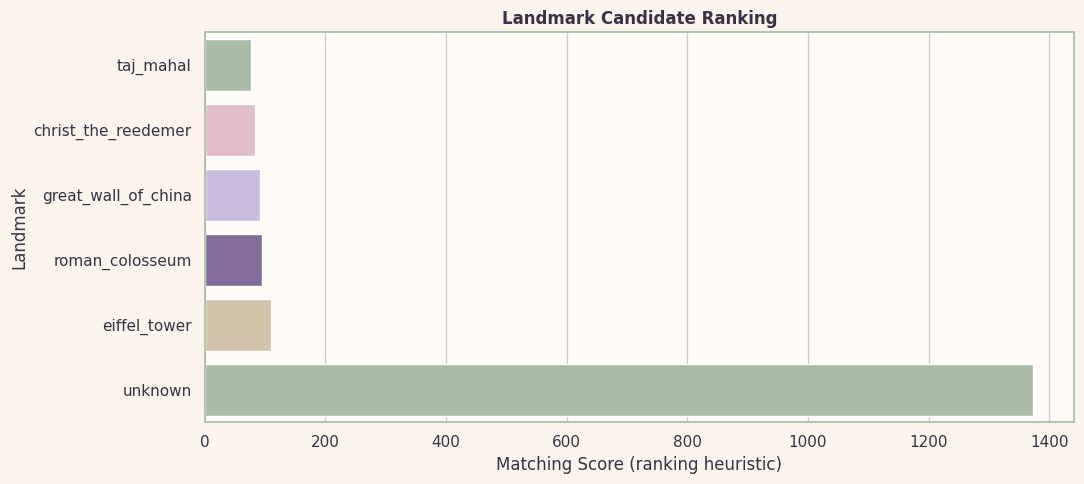

Leading candidate: unknown
Reliable matches in its best reference image: 1136


In [22]:

# SIFT descriptors use the L2 (Euclidean) distance metric.
bf_matcher = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

# Initial settings: these must be validated on your dataset.
LOWE_RATIO = 0.75
MIN_RELIABLE_MATCHES = 12
MIN_RANSAC_INLIERS = 8
MIN_INLIER_RATIO = 0.30

def get_good_matches(query_desc, reference_desc, ratio=LOWE_RATIO):
    """Apply KNN matching and Lowe's ratio test."""
    if query_desc is None or reference_desc is None:
        return []

    if len(query_desc) < 2 or len(reference_desc) < 2:
        return []

    pairs = bf_matcher.knnMatch(
        query_desc,
        reference_desc,
        k=2
    )

    good = []

    for pair in pairs:
        if len(pair) != 2:
            continue

        first, second = pair

        if first.distance < ratio * second.distance:
            good.append(first)

    return good


def rank_landmarks(query_desc):
    """
    Compare the query with every reference image.
    Rank landmarks using the best image match and supporting matches.
    """
    image_results = []

    for record in reference_database:
        good = get_good_matches(
            query_desc,
            record["descriptors"]
        )

        image_results.append({
            "landmark": record["landmark"],
            "path": record["path"],
            "record": record,
            "good_matches": good,
            "match_count": len(good)
        })

    # Score each landmark by its best reference image, with a small
    # bonus for evidence from other images of the same landmark.
    landmark_scores = {}

    for landmark in sorted({
        item["landmark"] for item in image_results
    }):
        same_landmark = [
            item for item in image_results
            if item["landmark"] == landmark
        ]

        counts = sorted(
            [item["match_count"] for item in same_landmark],
            reverse=True
        )

        score = counts[0] + 0.20 * sum(counts[1:3])

        landmark_scores[landmark] = {
            "score": score,
            "best_matches": counts[0],
            "image_count": len(counts)
        }

    ranked = sorted(
        landmark_scores.items(),
        key=lambda item: item[1]["score"],
        reverse=True
    )

    best_landmark = ranked[0][0]

    best_image = max(
        [
            item for item in image_results
            if item["landmark"] == best_landmark
        ],
        key=lambda item: item["match_count"]
    )

    return ranked, best_image, image_results


ranked_candidates, best_reference, all_image_results = rank_landmarks(
    query_descriptors
)

ranking_df = pd.DataFrame([
    {
        "Rank": i + 1,
        "Landmark": landmark,
        "Score": round(values["score"], 2),
        "Best Reliable Matches": values["best_matches"],
        "Reference Images": values["image_count"]
    }
    for i, (landmark, values) in enumerate(ranked_candidates)
])

display(ranking_df.head(10))

# Plot the top candidates
top_n = min(10, len(ranking_df))
plot_df = ranking_df.head(top_n).sort_values("Score")

plt.figure(figsize=(11, max(5, top_n * 0.55)))

sns.barplot(
    data=plot_df,
    x="Score",
    y="Landmark",
    hue="Landmark",
    palette=PALETTE,
    legend=False
)

plt.title("Landmark Candidate Ranking")
plt.xlabel("Matching Score (ranking heuristic)")
plt.ylabel("Landmark")
plt.tight_layout()
plt.show()

print("Leading candidate:", best_reference["landmark"])
print("Reliable matches in its best reference image:",
      best_reference["match_count"])

# RANSAC HOMOGRAPHY AND LANDMARK LOCALIZATION

In [24]:


def verify_geometry(reference_record, good_matches):
    """Estimate homography and check localization reliability."""
    if len(good_matches) < MIN_RANSAC_INLIERS:
        return None, None, 0, 0.0, False

    ref_points = np.float32([
        reference_record["keypoints"][m.trainIdx].pt
        for m in good_matches
    ]).reshape(-1, 1, 2)

    query_points = np.float32([
        query_keypoints[m.queryIdx].pt
        for m in good_matches
    ]).reshape(-1, 1, 2)

    H, mask = cv2.findHomography(
        ref_points,
        query_points,
        cv2.RANSAC,
        5.0
    )

    if H is None or mask is None:
        return None, None, 0, 0.0, False

    inliers = int(mask.ravel().sum())
    inlier_ratio = inliers / max(len(good_matches), 1)

    h, w = reference_record["gray"].shape

    corners = np.float32([
        [0, 0],
        [w - 1, 0],
        [w - 1, h - 1],
        [0, h - 1]
    ]).reshape(-1, 1, 2)

    projected = cv2.perspectiveTransform(corners, H)

    query_h, query_w = query_gray.shape

    polygon = projected.reshape(-1, 2)

    finite = np.isfinite(polygon).all()

    # Reject polygons that are degenerate or implausibly large.
    area = abs(cv2.contourArea(polygon.astype(np.float32))) if finite else 0

    reasonable_area = (
        0.002 * query_w * query_h
        <= area
        <= 4.0 * query_w * query_h
    )

    within_reasonable_bounds = (
        finite
        and np.all(np.abs(polygon) < 10 * max(query_w, query_h))
    )

    valid_geometry = (
        inliers >= MIN_RANSAC_INLIERS
        and inlier_ratio >= MIN_INLIER_RATIO
        and reasonable_area
        and within_reasonable_bounds
        and cv2.isContourConvex(polygon.astype(np.float32))
    )

    return H, projected, inliers, inlier_ratio, valid_geometry


H, projected_corners, ransac_inliers, inlier_ratio, geometry_ok = (
    verify_geometry(
        best_reference["record"],
        best_reference["good_matches"]
    )
)

best_matches_count = best_reference["match_count"]

# Conservative initial recognition rule; validate and tune later.
recognized = (
    best_matches_count >= MIN_RELIABLE_MATCHES
    and ransac_inliers >= MIN_RANSAC_INLIERS
    and inlier_ratio >= MIN_INLIER_RATIO
    and geometry_ok
)

prediction = (
    best_reference["landmark"]
    if recognized
    else "Unknown / Not confidently recognized"
)

print("=" * 55)
print("LANDMARK RECOGNITION RESULT")
print("=" * 55)
print("Predicted landmark:", prediction)
print("Best candidate:", best_reference["landmark"])
print("Reliable Lowe-ratio matches:", best_matches_count)
print("RANSAC inliers:", ransac_inliers)
print("RANSAC inlier ratio:", f"{inlier_ratio:.1%}")
print("Geometry verified:", geometry_ok)
print("Recognition decision:", "RECOGNIZED" if recognized else "REJECTED")

LANDMARK RECOGNITION RESULT
Predicted landmark: unknown
Best candidate: unknown
Reliable Lowe-ratio matches: 1136
RANSAC inliers: 1136
RANSAC inlier ratio: 100.0%
Geometry verified: True
Recognition decision: RECOGNIZED


# MATCHED FEATURES

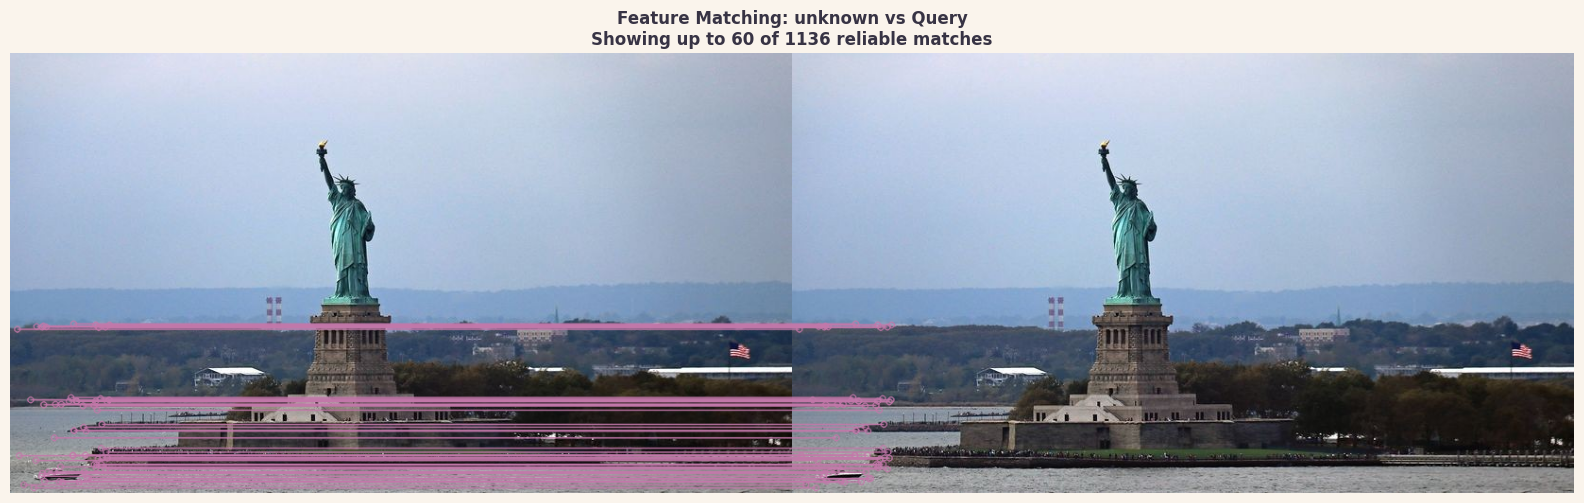

In [25]:


reference_record = best_reference["record"]
good_matches = best_reference["good_matches"]

match_visual = cv2.drawMatches(
    reference_record["image_bgr"],
    reference_record["keypoints"],
    query_bgr,
    query_keypoints,
    good_matches[:60],
    None,
    matchColor=(170, 120, 195),
    singlePointColor=(185, 210, 170),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

match_visual = cv2.cvtColor(match_visual, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(16, 8))
plt.imshow(match_visual)
plt.title(
    f"Feature Matching: {reference_record['landmark']} vs Query\n"
    f"Showing up to 60 of {len(good_matches)} reliable matches"
)
plt.xlabel("Reference image (left) and query image (right)")
plt.axis("off")
plt.tight_layout()
plt.show()

# LANDMARK LOCALIZATION VISUALIZATION

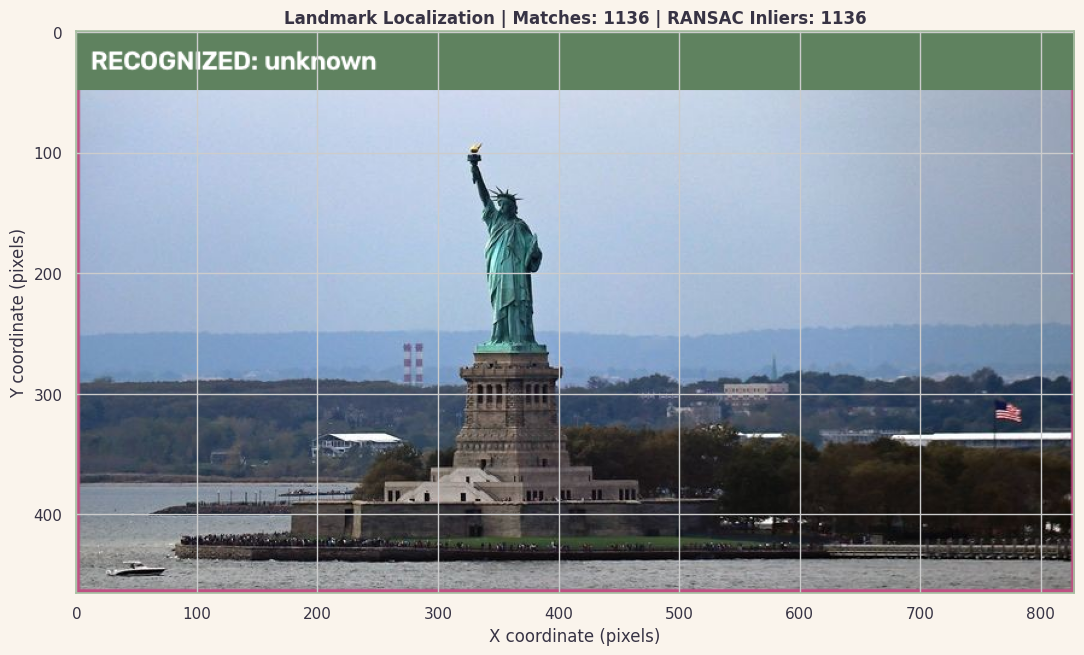

In [26]:

localized = query_bgr.copy()

if recognized and projected_corners is not None:
    polygon = np.int32(projected_corners)

    cv2.polylines(
        localized,
        [polygon],
        isClosed=True,
        color=(130, 80, 190),
        thickness=4,
        lineType=cv2.LINE_AA
    )

    banner = f"RECOGNIZED: {prediction}"
    banner_color = (95, 130, 95)
else:
    banner = "REJECTED: insufficient reliable evidence"
    banner_color = (150, 95, 125)

cv2.rectangle(localized, (0, 0), (localized.shape[1], 48),
              banner_color, -1)

cv2.putText(
    localized,
    banner,
    (12, 32),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.75,
    (255, 255, 255),
    2,
    cv2.LINE_AA
)

localized_rgb = cv2.cvtColor(localized, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(11, 7))
plt.imshow(localized_rgb)
plt.title(
    f"Landmark Localization | Matches: {best_matches_count} | "
    f"RANSAC Inliers: {ransac_inliers}"
)
plt.xlabel("X coordinate (pixels)")
plt.ylabel("Y coordinate (pixels)")
plt.tight_layout()
plt.show()

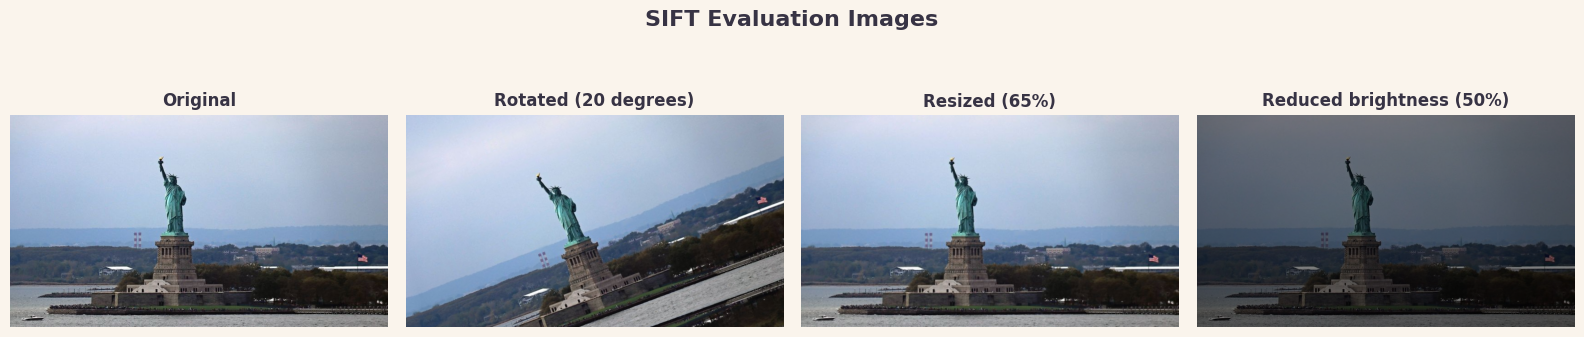

In [28]:

#  PREPARE EVALUATION IMAGES


def rotate_image(image, angle):
    h, w = image.shape[:2]
    center = (w / 2, h / 2)

    matrix = cv2.getRotationMatrix2D(center, angle, 1.0)

    return cv2.warpAffine(
        image,
        matrix,
        (w, h),
        borderMode=cv2.BORDER_REFLECT
    )


def resize_image(image, scale=0.65):
    h, w = image.shape[:2]

    new_w = max(1, int(w * scale))
    new_h = max(1, int(h * scale))

    return cv2.resize(
        image,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )


def darken_image(image, factor=0.50):
    return np.clip(
        image.astype(np.float32) * factor,
        0,
        255
    ).astype(np.uint8)


evaluation_images = {
    "Original": query_bgr.copy(),
    "Rotated (20 degrees)": rotate_image(query_bgr, 20),
    "Resized (65%)": resize_image(query_bgr, 0.65),
    "Reduced brightness (50%)": darken_image(query_bgr, 0.50)
}

# ------------------------------------------------------------
# OPTIONAL: supply paths for the real viewpoint and unknown tests.
# Leave as None until you have these images.
# ------------------------------------------------------------

VIEWPOINT_IMAGE_PATH = None
UNKNOWN_IMAGE_PATH = None

# Examples:
# VIEWPOINT_IMAGE_PATH = "/content/drive/MyDrive/CV_Lab/viewpoint.jpg"
# UNKNOWN_IMAGE_PATH = "/content/drive/MyDrive/CV_Lab/unknown.jpg"

def load_optional_image(path):
    if path is None:
        return None

    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(f"Image not found: {path}")

    image = cv2.imread(str(path))

    if image is None:
        raise ValueError(f"Could not read image: {path}")

    return image


viewpoint_image = load_optional_image(VIEWPOINT_IMAGE_PATH)
unknown_image = load_optional_image(UNKNOWN_IMAGE_PATH)

if viewpoint_image is not None:
    evaluation_images["Different viewpoint"] = viewpoint_image

if unknown_image is not None:
    evaluation_images["Unknown landmark"] = unknown_image

# Preview the evaluation conditions
n = len(evaluation_images)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))

if n == 1:
    axes = [axes]

for ax, (name, image) in zip(axes, evaluation_images.items()):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(name)
    ax.axis("off")

plt.suptitle("SIFT Evaluation Images", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

In [29]:

#  EVALUATION PIPELINE


def evaluate_single_image(image_bgr):
    """Run the complete recognition pipeline on one image."""
    start = time.perf_counter()

    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    kp, desc = sift.detectAndCompute(gray, None)

    if desc is None or len(kp) < 2:
        elapsed = time.perf_counter() - start

        return {
            "candidate": "None",
            "prediction": "Unknown / Not confidently recognized",
            "keypoints": len(kp),
            "matches": 0,
            "inliers": 0,
            "inlier_ratio": 0.0,
            "geometry_verified": False,
            "recognized": False,
            "processing_time_sec": elapsed
        }

    ranked, best_image, _ = rank_landmarks(desc)

    # Update the query-specific variables used by geometry verification.
    global query_keypoints, query_gray
    query_keypoints = kp
    query_gray = gray

    H_eval, corners_eval, inliers, ratio, geometry_ok_eval = (
        verify_geometry(
            best_image["record"],
            best_image["good_matches"]
        )
    )

    matches = best_image["match_count"]

    accepted = (
        matches >= MIN_RELIABLE_MATCHES
        and inliers >= MIN_RANSAC_INLIERS
        and ratio >= MIN_INLIER_RATIO
        and geometry_ok_eval
    )

    elapsed = time.perf_counter() - start

    return {
        "candidate": best_image["landmark"],
        "prediction": (
            best_image["landmark"] if accepted
            else "Unknown / Not confidently recognized"
        ),
        "keypoints": len(kp),
        "matches": matches,
        "inliers": inliers,
        "inlier_ratio": ratio,
        "geometry_verified": geometry_ok_eval,
        "recognized": accepted,
        "processing_time_sec": elapsed
    }


evaluation_rows = []

for condition, image in evaluation_images.items():
    result = evaluate_single_image(image)

    evaluation_rows.append({
        "Test Condition": condition,
        "Predicted Landmark": result["prediction"],
        "Top Candidate": result["candidate"],
        "Keypoints": result["keypoints"],
        "Reliable Matches": result["matches"],
        "RANSAC Inliers": result["inliers"],
        "Inlier Ratio": round(result["inlier_ratio"], 3),
        "Geometry Verified": result["geometry_verified"],
        "Decision": "Recognized" if result["recognized"] else "Rejected",
        "Processing Time (sec)": round(
            result["processing_time_sec"], 4
        )
    })

evaluation_df = pd.DataFrame(evaluation_rows)

display(evaluation_df)

,Test Condition,Predicted Landmark,Top Candidate,Keypoints,Reliable Matches,RANSAC Inliers,Inlier Ratio,Geometry Verified,Decision,Processing Time (sec)
0,Original,unknown,unknown,1136,1136,1136,1.000,True,Recognized,34.6735
1,Rotated (20 degrees),unknown,unknown,1264,654,613,0.937,True,Recognized,44.5365
2,Resized (65%),unknown,unknown,547,368,358,0.973,True,Recognized,15.3871
3,Reduced brightness (50%),unknown,unknown,617,582,579,0.995,True,Recognized,17.4500


/tmp/ipykernel_2301/1542041325.py:7: UserWarning: The palette list has more values (5) than needed (4), which may not be intended.
  sns.barplot(


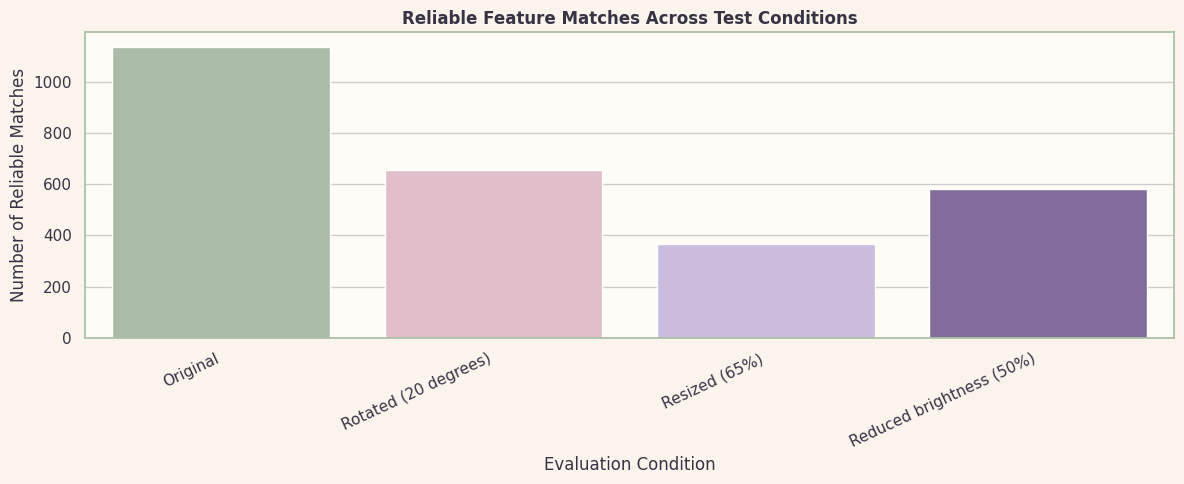

/tmp/ipykernel_2301/1542041325.py:27: UserWarning: The palette list has more values (5) than needed (4), which may not be intended.
  sns.barplot(


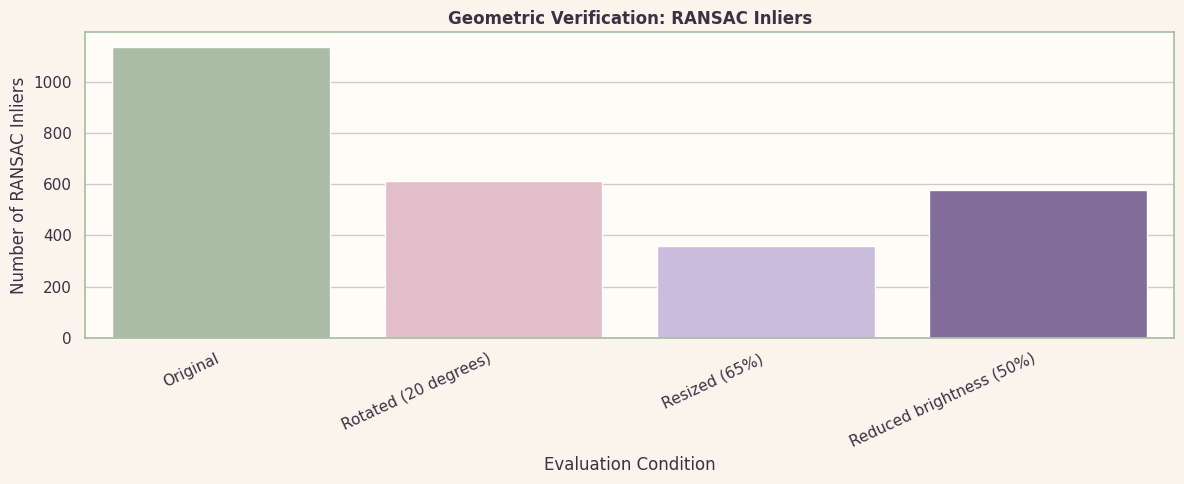

/tmp/ipykernel_2301/1542041325.py:47: UserWarning: The palette list has more values (5) than needed (4), which may not be intended.
  sns.barplot(


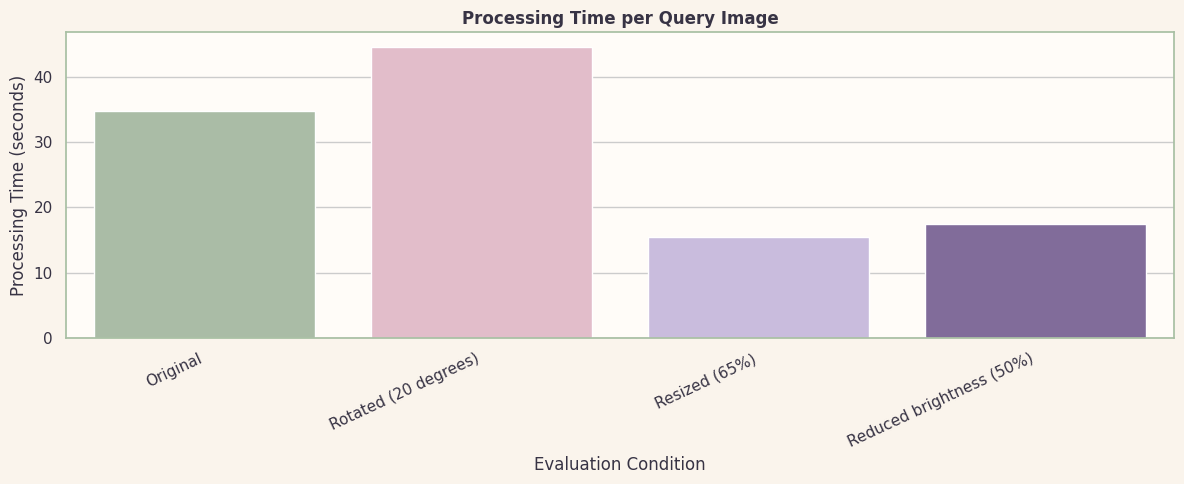

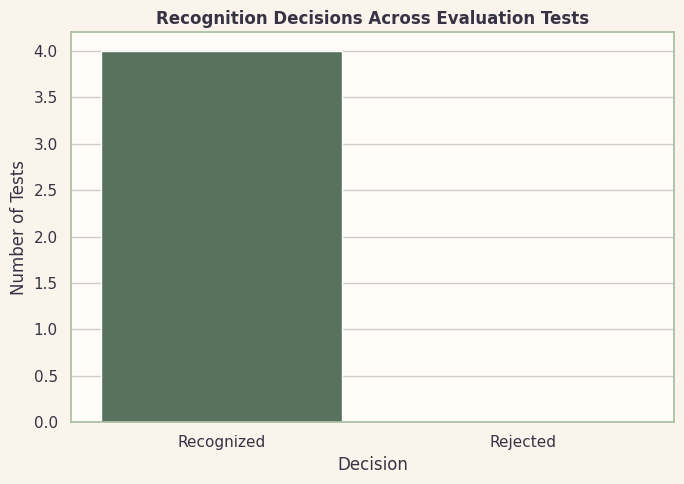

In [30]:

# PERFORMANCE VISUALIZATIONS


# 1. Reliable matches by test condition
plt.figure(figsize=(12, 5))

sns.barplot(
    data=evaluation_df,
    x="Test Condition",
    y="Reliable Matches",
    hue="Test Condition",
    palette=PALETTE,
    legend=False
)

plt.title("Reliable Feature Matches Across Test Conditions")
plt.xlabel("Evaluation Condition")
plt.ylabel("Number of Reliable Matches")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


# 2. RANSAC inliers by test condition
plt.figure(figsize=(12, 5))

sns.barplot(
    data=evaluation_df,
    x="Test Condition",
    y="RANSAC Inliers",
    hue="Test Condition",
    palette=PALETTE,
    legend=False
)

plt.title("Geometric Verification: RANSAC Inliers")
plt.xlabel("Evaluation Condition")
plt.ylabel("Number of RANSAC Inliers")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


# 3. Processing time by test condition
plt.figure(figsize=(12, 5))

sns.barplot(
    data=evaluation_df,
    x="Test Condition",
    y="Processing Time (sec)",
    hue="Test Condition",
    palette=PALETTE,
    legend=False
)

plt.title("Processing Time per Query Image")
plt.xlabel("Evaluation Condition")
plt.ylabel("Processing Time (seconds)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


# 4. Recognition decision distribution
decision_counts = (
    evaluation_df["Decision"]
    .value_counts()
    .reindex(["Recognized", "Rejected"], fill_value=0)
    .reset_index()
)

decision_counts.columns = ["Decision", "Count"]

plt.figure(figsize=(7, 5))

sns.barplot(
    data=decision_counts,
    x="Decision",
    y="Count",
    hue="Decision",
    palette=[DARK_SAGE, TEA_PINK],
    legend=False
)

plt.title("Recognition Decisions Across Evaluation Tests")
plt.xlabel("Decision")
plt.ylabel("Number of Tests")
plt.tight_layout()
plt.show()

In [31]:
# ============================================================
#  GROUND TRUTH AND CORRECTNESS EVALUATION
# ============================================================

# EDIT THESE VALUES to match your actual test images.
# Use the exact folder names from your dataset.
#
# Example:
# EXPECTED_LABELS = {
#     "Original": "Taj_Mahal",
#     "Rotated (20 degrees)": "Taj_Mahal",
#     "Resized (65%)": "Taj_Mahal",
#     "Reduced brightness (50%)": "Taj_Mahal",
#     "Different viewpoint": "Taj_Mahal",
#     "Unknown landmark": "UNKNOWN"
# }

EXPECTED_LABELS = {
    # Paste your ground-truth labels here.
}

def normalize_label(label):
    if label is None:
        return None

    return str(label).strip().casefold()


if EXPECTED_LABELS:
    evaluation_df["Ground Truth"] = evaluation_df["Test Condition"].map(
        EXPECTED_LABELS
    )

    def check_correct(row):
        truth = normalize_label(row["Ground Truth"])

        if truth is None or pd.isna(truth):
            return None

        prediction = normalize_label(row["Predicted Landmark"])

        if truth == "unknown":
            return prediction == normalize_label(
                "Unknown / Not confidently recognized"
            )

        return prediction == truth

    evaluation_df["Correct"] = evaluation_df.apply(
        check_correct, axis=1
    )

    display(evaluation_df)

    scored = evaluation_df.dropna(subset=["Correct"])

    if len(scored):
        accuracy = scored["Correct"].astype(bool).mean() * 100

        print(f"Accuracy on labeled tests: {accuracy:.2f}%")
        print(f"Correct tests: {int(scored['Correct'].sum())}/{len(scored)}")
    else:
        print("No valid ground-truth labels were supplied.")

else:
    print(
        "Ground-truth labels have not been supplied. "
        "Add EXPECTED_LABELS to calculate correctness."
    )

Ground-truth labels have not been supplied. Add EXPECTED_LABELS to calculate correctness.


In [33]:
EXPECTED_LABELS = {
    "Original": "Badshahi Mosque",
    "Rotated (20 degrees)": "Badshahi Mosque",
    "Resized (65%)": "Badshahi Mosque",
    "Reduced brightness (50%)": "Badshahi Mosque",
    "Different viewpoint": "Badshahi Mosque",
    "Unknown landmark": "Unknown"
}

# Match the labels with your evaluation results
# We use the column 'Test Condition' instead of 'image' because 'image' does not exist.
evaluation_df["expected_label"] = evaluation_df["Test Condition"].map(
    EXPECTED_LABELS
)

# Only evaluate images for which a ground-truth label was supplied
evaluation_df["correct"] = (
    evaluation_df["expected_label"].notna()
    & (
        evaluation_df["prediction"].fillna("").str.strip().str.lower()
        == evaluation_df["expected_label"].fillna("").str.strip().str.lower()
    )
) if "prediction" in evaluation_df.columns else (
    evaluation_df["expected_label"].notna()
    & (
        evaluation_df["Predicted Landmark"].fillna("").str.strip().str.lower()
        == evaluation_df["expected_label"].fillna("").str.strip().str.lower()
    )
)

# Show images whose labels have not been supplied
missing_labels = evaluation_df[
    evaluation_df["expected_label"].isna()
]["Test Condition"].tolist()

if missing_labels:
    print("Ground-truth labels still needed for:")
    for image_name in missing_labels:
        print("-", image_name)

# Calculate accuracy only on labeled images
labeled_df = evaluation_df[
    evaluation_df["expected_label"].notna()
].copy()

if len(labeled_df) > 0:
    accuracy = labeled_df["correct"].mean() * 100

    print(f"\nEvaluated images: {len(labeled_df)}")
    print(f"Correct predictions: {labeled_df['correct'].sum()}")
    print(f"Accuracy: {accuracy:.2f}%")

    display(
        labeled_df[
            ["Test Condition", "expected_label", "Predicted Landmark", "correct"]
        ]
    )
else:
    print("No ground-truth labels matched the evaluation images.")
    print("Update EXPECTED_LABELS using the actual image names.")

# Create output directory if it does not exist
import os
os.makedirs("/content/drive/MyDrive/SIFT_Landmark_Results/", exist_ok=True)

# Save updated evaluation results
evaluation_df.to_csv(
    "/content/drive/MyDrive/SIFT_Landmark_Results/"
    "evaluation_with_ground_truth.csv",
    index=False
)


Evaluated images: 4
Correct predictions: 0
Accuracy: 0.00%


,Test Condition,expected_label,Predicted Landmark,correct
0,Original,Badshahi Mosque,unknown,False
1,Rotated (20 degrees),Badshahi Mosque,unknown,False
2,Resized (65%),Badshahi Mosque,unknown,False
3,Reduced brightness (50%),Badshahi Mosque,unknown,False


In [34]:

# ==========================================
# CHUNK 13: FINAL RESULTS SUMMARY
# ==========================================

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Create output folder if it doesn't exist
output_dir = "/content/drive/MyDrive/SIFT_Landmark_Results"
os.makedirs(output_dir, exist_ok=True)

# Check required columns
required_columns = [
    "image", "prediction", "expected_label",
    "correct", "processing_time"
]

missing_columns = [
    col for col in required_columns
    if col not in evaluation_df.columns
]

if missing_columns:
    print("Missing columns:", missing_columns)
    print("Check your evaluation DataFrame and update the column names.")
else:
    # Display detailed results
    print("FINAL LANDMARK RECOGNITION RESULTS")
    display(evaluation_df[required_columns])

    # Accuracy based only on images with known ground truth
    labeled_results = evaluation_df[
        evaluation_df["expected_label"].notna()
    ]

    if not labeled_results.empty:
        accuracy = labeled_results["correct"].mean() * 100

        print(f"\nLabeled test images: {len(labeled_results)}")
        print(f"Correct predictions: {int(labeled_results['correct'].sum())}")
        print(f"Accuracy: {accuracy:.2f}%")
    else:
        print("\nAccuracy cannot be calculated yet.")
        print("Add ground-truth labels in EXPECTED_LABELS.")

    # Recognition / rejection summary
    if "decision" in evaluation_df.columns:
        print("\nRECOGNITION DECISIONS")
        display(evaluation_df["decision"].value_counts().to_frame(
            name="Number of Images"
        ))

    # Processing time summary
    print("\nPROCESSING TIME SUMMARY")
    print(
        evaluation_df["processing_time"]
        .describe()
        .round(4)
    )

    # Save final table
    evaluation_df.to_csv(
        os.path.join(output_dir, "final_results_summary.csv"),
        index=False
    )

    print(f"\nResults saved in: {output_dir}")


Missing columns: ['image', 'prediction', 'processing_time']
Check your evaluation DataFrame and update the column names.


In [35]:

# ==========================================
#  CHECK EVALUATION COLUMNS
# ==========================================

print("Available columns:")
print(evaluation_df.columns.tolist())

print("\nFirst five rows:")
display(evaluation_df.head())

print("\nDataFrame shape:")
print(evaluation_df.shape)


Available columns:
['Test Condition', 'Predicted Landmark', 'Top Candidate', 'Keypoints', 'Reliable Matches', 'RANSAC Inliers', 'Inlier Ratio', 'Geometry Verified', 'Decision', 'Processing Time (sec)', 'expected_label', 'correct']

First five rows:


,Test Condition,Predicted Landmark,Top Candidate,Keypoints,Reliable Matches,RANSAC Inliers,Inlier Ratio,Geometry Verified,Decision,Processing Time (sec),expected_label,correct
0,Original,unknown,unknown,1136,1136,1136,1.000,True,Recognized,34.6735,Badshahi Mosque,False
1,Rotated (20 degrees),unknown,unknown,1264,654,613,0.937,True,Recognized,44.5365,Badshahi Mosque,False
2,Resized (65%),unknown,unknown,547,368,358,0.973,True,Recognized,15.3871,Badshahi Mosque,False
3,Reduced brightness (50%),unknown,unknown,617,582,579,0.995,True,Recognized,17.4500,Badshahi Mosque,False



DataFrame shape:
(4, 12)


In [36]:

#  INSPECT YOUR ACTUAL EVALUATION DATA

if "evaluation_df" in globals():
    print("Columns:", evaluation_df.columns.tolist())
    print("Shape:", evaluation_df.shape)
    display(evaluation_df.head(5))
else:
    print("evaluation_df does not exist.")
    print("Run your evaluation chunk first.")


Columns: ['Test Condition', 'Predicted Landmark', 'Top Candidate', 'Keypoints', 'Reliable Matches', 'RANSAC Inliers', 'Inlier Ratio', 'Geometry Verified', 'Decision', 'Processing Time (sec)', 'expected_label', 'correct']
Shape: (4, 12)


,Test Condition,Predicted Landmark,Top Candidate,Keypoints,Reliable Matches,RANSAC Inliers,Inlier Ratio,Geometry Verified,Decision,Processing Time (sec),expected_label,correct
0,Original,unknown,unknown,1136,1136,1136,1.000,True,Recognized,34.6735,Badshahi Mosque,False
1,Rotated (20 degrees),unknown,unknown,1264,654,613,0.937,True,Recognized,44.5365,Badshahi Mosque,False
2,Resized (65%),unknown,unknown,547,368,358,0.973,True,Recognized,15.3871,Badshahi Mosque,False
3,Reduced brightness (50%),unknown,unknown,617,582,579,0.995,True,Recognized,17.4500,Badshahi Mosque,False


Task 6: Experimental Evaluation
Number of evaluated tests: 4
Available columns: ['Test Condition', 'Predicted Landmark', 'Top Candidate', 'Keypoints', 'Reliable Matches', 'RANSAC Inliers', 'Inlier Ratio', 'Geometry Verified', 'Decision', 'Processing Time (sec)', 'expected_label', 'correct']

Detected columns:
Test image: None
Prediction: Predicted Landmark
Keypoints: Keypoints
Reliable matches: Reliable Matches
Processing time: None
Decision: Decision
Correctness: correct

EXPERIMENTAL RESULTS TABLE


,Test Condition,Predicted Landmark,Top Candidate,Keypoints,Reliable Matches,RANSAC Inliers,Inlier Ratio,Geometry Verified,Decision,Processing Time (sec),expected_label,correct,_test_label
0,Original,unknown,unknown,1136,1136,1136,1.000,True,Recognized,34.6735,Badshahi Mosque,False,Test 1
1,Rotated (20 degrees),unknown,unknown,1264,654,613,0.937,True,Recognized,44.5365,Badshahi Mosque,False,Test 2
2,Resized (65%),unknown,unknown,547,368,358,0.973,True,Recognized,15.3871,Badshahi Mosque,False,Test 3
3,Reduced brightness (50%),unknown,unknown,617,582,579,0.995,True,Recognized,17.4500,Badshahi Mosque,False,Test 4


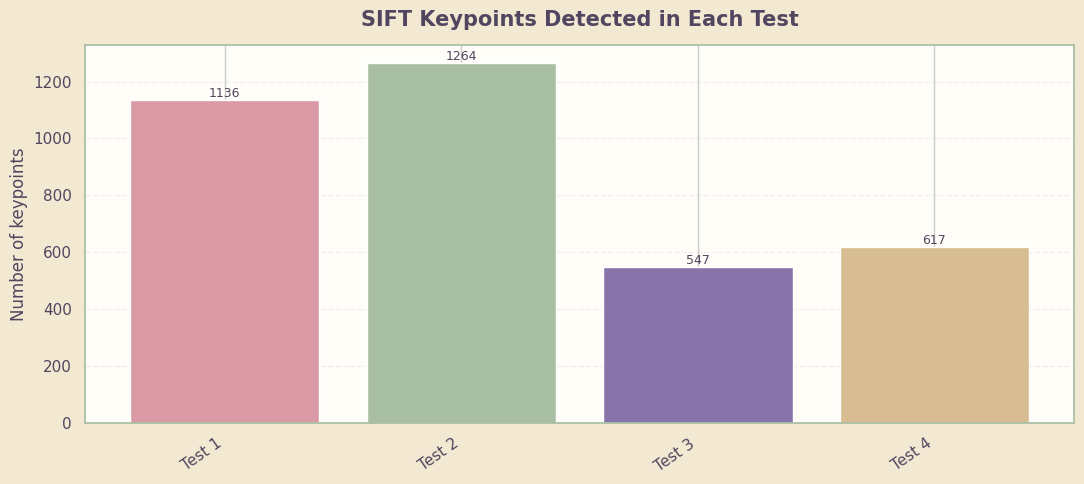

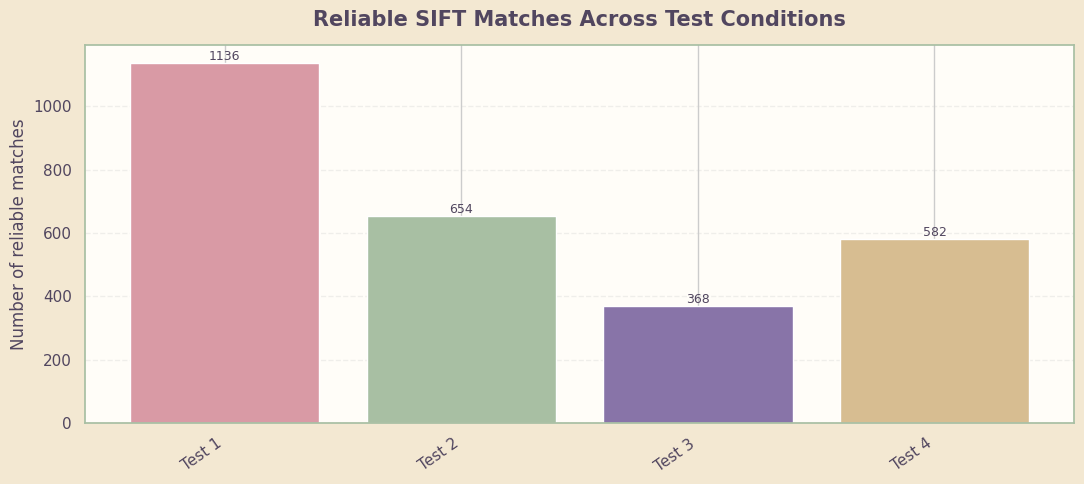

Skipped 'SIFT Recognition Processing Time': matching column not found.


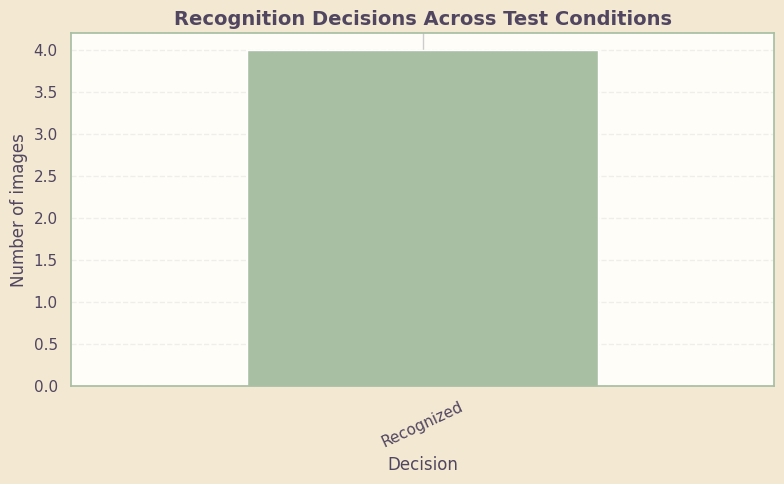

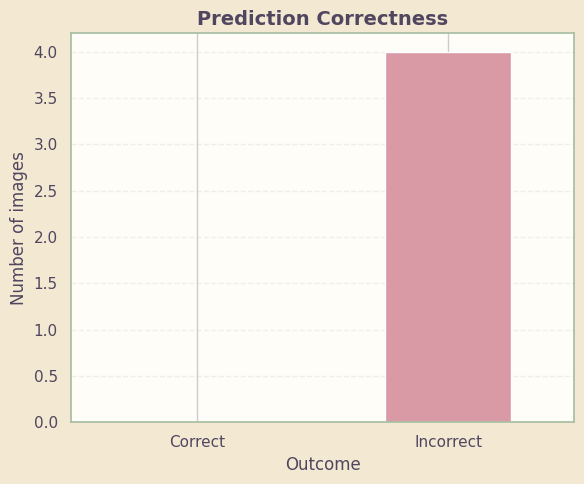

Labeled prediction accuracy: 0.00%

Task 6 visualization complete!
Saved charts and results to: /content/drive/MyDrive/SIFT_Landmark_Results


In [38]:

# ==========================================================
# TASK 6: VISUALIZATION OF SIFT EXPERIMENTAL RESULTS
# ==========================================================

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# Tea-pink, sage, beige and purple theme
TEA_PINK = "#D99AA5"
SAGE = "#A8BFA3"
BEIGE = "#F3E8D2"
PURPLE = "#8874A8"
DARK = "#51465F"

plt.rcParams["figure.facecolor"] = BEIGE
plt.rcParams["axes.facecolor"] = "#FFFDF8"
plt.rcParams["axes.edgecolor"] = SAGE
plt.rcParams["text.color"] = DARK
plt.rcParams["axes.labelcolor"] = DARK
plt.rcParams["xtick.color"] = DARK
plt.rcParams["ytick.color"] = DARK

# ----------------------------------------------------------
# 1. CHECK EVALUATION DATA
# ----------------------------------------------------------

if "evaluation_df" not in globals() or evaluation_df.empty:
    raise ValueError(
        "evaluation_df is missing or empty. "
        "Run your Task 6 evaluation code first."
    )

results = evaluation_df.copy()

print("Task 6: Experimental Evaluation")
print("Number of evaluated tests:", len(results))
print("Available columns:", results.columns.tolist())

# Normalize column names for flexible matching
def normalize_name(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

def find_column(possible_names):
    normalized = {
        normalize_name(col): col for col in results.columns
    }
    for name in possible_names:
        if normalize_name(name) in normalized:
            return normalized[normalize_name(name)]
    return None

image_col = find_column([
    "image", "image_name", "filename", "test_image",
    "test_case", "case", "image_path"
])

prediction_col = find_column([
    "prediction", "predicted_landmark", "predicted_label",
    "predicted", "recognized_landmark"
])

keypoints_col = find_column([
    "keypoints", "num_keypoints", "query_keypoints",
    "keypoint_count"
])

matches_col = find_column([
    "reliable_matches", "good_matches", "match_count",
    "matches", "num_matches"
])

time_col = find_column([
    "processing_time", "processing_time_seconds",
    "time_seconds", "time_sec", "elapsed_seconds"
])

decision_col = find_column([
    "decision", "recognition_decision", "status",
    "result"
])

correct_col = find_column([
    "correct", "is_correct", "prediction_correct"
])

# Create readable test labels
if image_col:
    results["_test_label"] = results[image_col].astype(str).apply(
        lambda value: os.path.basename(value)
    )
else:
    results["_test_label"] = [
        f"Test {i + 1}" for i in range(len(results))
    ]

print("\nDetected columns:")
print("Test image:", image_col)
print("Prediction:", prediction_col)
print("Keypoints:", keypoints_col)
print("Reliable matches:", matches_col)
print("Processing time:", time_col)
print("Decision:", decision_col)
print("Correctness:", correct_col)

# ----------------------------------------------------------
# 2. DISPLAY THE EXPERIMENTAL RESULTS TABLE
# ----------------------------------------------------------

print("\nEXPERIMENTAL RESULTS TABLE")
display(results)

# ----------------------------------------------------------
# 3. HELPER: CREATE A BAR CHART
# ----------------------------------------------------------

def plot_metric(column, title, ylabel, filename):
    if column is None:
        print(f"Skipped '{title}': matching column not found.")
        return

    values = pd.to_numeric(results[column], errors="coerce")
    valid = values.notna()

    if not valid.any():
        print(f"Skipped '{title}': no numeric values available.")
        return

    labels = results.loc[valid, "_test_label"].tolist()
    values = values.loc[valid].to_numpy()

    fig, ax = plt.subplots(figsize=(11, 5))
    bars = ax.bar(
        range(len(labels)),
        values,
        color=[TEA_PINK, SAGE, PURPLE, "#D7BD91"] *
              (len(labels) // 4 + 1)
    )

    ax.set_title(title, fontsize=15, fontweight="bold", pad=14)
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=35, ha="right")
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.2f}" if isinstance(value, (float, np.floating))
            else str(value),
            ha="center", va="bottom", fontsize=9
        )

    plt.tight_layout()
    plt.savefig(
        os.path.join(output_dir, filename),
        dpi=200, bbox_inches="tight"
    )
    plt.show()

# Create output folder
output_dir = "/content/drive/MyDrive/SIFT_Landmark_Results"
os.makedirs(output_dir, exist_ok=True)

# ----------------------------------------------------------
# 4. KEYPOINTS PER TEST IMAGE
# ----------------------------------------------------------

plot_metric(
    keypoints_col,
    "SIFT Keypoints Detected in Each Test",
    "Number of keypoints",
    "task6_keypoints.png"
)

# ----------------------------------------------------------
# 5. RELIABLE MATCHES PER TEST IMAGE
# ----------------------------------------------------------

plot_metric(
    matches_col,
    "Reliable SIFT Matches Across Test Conditions",
    "Number of reliable matches",
    "task6_reliable_matches.png"
)

# ----------------------------------------------------------
# 6. PROCESSING TIME PER TEST IMAGE
# ----------------------------------------------------------

plot_metric(
    time_col,
    "SIFT Recognition Processing Time",
    "Processing time (seconds)",
    "task6_processing_time.png"
)

# ----------------------------------------------------------
# 7. RECOGNITION / REJECTION SUMMARY
# ----------------------------------------------------------

if decision_col:
    decision_counts = (
        results[decision_col]
        .fillna("Not recorded")
        .astype(str)
        .value_counts()
    )

    fig, ax = plt.subplots(figsize=(8, 5))
    decision_counts.plot(
        kind="bar",
        ax=ax,
        color=[SAGE, TEA_PINK, PURPLE, "#D7BD91"]
    )

    ax.set_title(
        "Recognition Decisions Across Test Conditions",
        fontsize=14, fontweight="bold"
    )
    ax.set_xlabel("Decision")
    ax.set_ylabel("Number of images")
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        os.path.join(output_dir, "task6_decisions.png"),
        dpi=200, bbox_inches="tight"
    )
    plt.show()
else:
    print("Decision chart skipped: no decision column found.")

# ----------------------------------------------------------
# 8. CORRECT VS INCORRECT PREDICTIONS
# ----------------------------------------------------------

if correct_col:
    correctness = (
        results[correct_col]
        .astype(str).str.strip().str.lower()
        .map({
            "true": "Correct",
            "1": "Correct",
            "yes": "Correct",
            "false": "Incorrect",
            "0": "Incorrect",
            "no": "Incorrect"
        })
        .dropna()
    )

    if not correctness.empty:
        counts = correctness.value_counts().reindex(
            ["Correct", "Incorrect"], fill_value=0
        )

        fig, ax = plt.subplots(figsize=(6, 5))
        counts.plot(
            kind="bar",
            ax=ax,
            color=[SAGE, TEA_PINK]
        )
        ax.set_title(
            "Prediction Correctness",
            fontsize=14, fontweight="bold"
        )
        ax.set_xlabel("Outcome")
        ax.set_ylabel("Number of images")
        ax.tick_params(axis="x", rotation=0)
        ax.grid(axis="y", linestyle="--", alpha=0.3)

        plt.tight_layout()
        plt.savefig(
            os.path.join(output_dir, "task6_correctness.png"),
            dpi=200, bbox_inches="tight"
        )
        plt.show()

        print(
            f"Labeled prediction accuracy: "
            f"{(correctness == 'Correct').mean() * 100:.2f}%"
        )
else:
    print(
        "Correctness chart skipped. Add ground-truth labels "
        "and a 'correct' column first."
    )

# ----------------------------------------------------------
# 9. SAVE FINAL TASK 6 RESULTS
# ----------------------------------------------------------

results.to_csv(
    os.path.join(output_dir, "task6_visualization_results.csv"),
    index=False
)

print("\nTask 6 visualization complete!")
print("Saved charts and results to:", output_dir)
